# ASL Word-Level Recognition (15 Dynamic Words) — Kinematic Conformer + Academic Evaluation

**Target Vocabulary (15 Visually Distinct Signs):**  
`eat`, `family`, `finish`, `friend`, `hello`, `help`, `love`, `more`, `no`, `please`, `stop`, `thank you`, `want`, `water`, `yes`

### Architecture & Academic Pipeline
1. **Multi-Source Curation:** Selective HTTP-range extraction from **ASL Citizen** (52 Deaf signers, webcam framing) + optional **WLASL** + optional **Personal Webcam Calibration** (`calibration_data/words/`).
2. **Domain-Invariant Kinematics (688-dim / frame):** MediaPipe Tasks `HandLandmarker` + `PoseLandmarker` extracting torso-normalized 3D coordinates, wrist-local hand coordinates, 30 finger joint angles, 16 hand-to-face/cross-hand distances, plus time-normalized velocity & acceleration over `T = 48` frames.
3. **3-Way Academic Benchmark (Same Clips & Signer-Disjoint Splits):**
   - **Baseline 1:** `ResNet-18 + BiGRU` on raw `16×112×112` RGB video frames.
   - **Baseline 2:** `Pose BiGRU` on raw `171`-dim torso-normalized landmarks.
   - **Proposed Primary Model:** `Kinematic Conformer` (Macaron FFN + Multi-Head Self-Attention + Depthwise 1D Conv + Attention Pooling + EMA + Mixup).
4. **Academic Diagnostics & Export:** Confusion Matrix, Per-Word F1 ranking, Temporal & Feature-Group Saliency, UMAP embeddings, Failure Analysis, and verified **ONNX** export (`asl_words_conformer.onnx`) for your local Windows OpenCV app.


In [1]:
# @title 1. Install Dependencies, Check GPU/High-RAM & Mount Google Drive
!pip install -q mediapipe onnx onnxruntime remotezip kagglehub umap-learn tqdm scikit-learn seaborn opencv-python-headless psutil

import os
import random
import shutil
import json
import re
import time
import warnings
import multiprocessing
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import cv2
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# Reproducibility & A100/L4 TF32 acceleration
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TOTAL_RAM_GB = psutil.virtual_memory().total / 1e9
AVAIL_RAM_GB = psutil.virtual_memory().available / 1e9
CPU_CORES = os.cpu_count() or 2
GPU_VRAM_GB = (
    torch.cuda.get_device_properties(0).total_memory / 1e9
    if torch.cuda.is_available()
    else 0.0
)
HIGH_RAM = TOTAL_RAM_GB >= 24.0
EXTRACTION_WORKERS = min(8, max(1, CPU_CORES - 1))
LOADER_WORKERS = min(6, max(2, CPU_CORES // 2))
KIN_BATCH_SIZE = 64 if GPU_VRAM_GB >= 20.0 else 32
RGB_BATCH_SIZE = 32 if GPU_VRAM_GB >= 20.0 else 16

print(f"PyTorch: {torch.__version__} | Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} | VRAM: {GPU_VRAM_GB:.1f} GB")
import mediapipe as mp
print(f"MediaPipe: {mp.__version__} | CPU cores: {CPU_CORES} | RAM: {TOTAL_RAM_GB:.1f} GB total ({AVAIL_RAM_GB:.1f} GB free) | High-RAM: {HIGH_RAM}")
print(f"Auto-tuned -> Extraction workers: {EXTRACTION_WORKERS} | Loader workers: {LOADER_WORKERS} | Batch (Kin/RGB): {KIN_BATCH_SIZE}/{RGB_BATCH_SIZE}")

# Mount Google Drive for persistent dataset cache, checkpoints, and calibration clips
USE_DRIVE = True  # @param {type:"boolean"}
DRIVE_BASE = Path("/content/ASL_Project")
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_BASE = Path("/content/drive/MyDrive/ASL_Project")
    except Exception as exc:
        print("Drive mount skipped:", exc)

WORK_DIR = DRIVE_BASE / "words_conformer"
RAW_DIR = Path("/content/raw_asl_words")
CAL_DIR = DRIVE_BASE / "calibration_data" / "words"
FIG_DIR = WORK_DIR / "figures"
EXPORT_DIR = WORK_DIR / "export"
for d in [WORK_DIR, RAW_DIR, FIG_DIR, EXPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "axes.grid": True, "grid.alpha": 0.25})
print("Workspace:", WORK_DIR)


PyTorch: 2.14.1+cu130 | Device: cuda
GPU: NVIDIA L4 | VRAM: 23.7 GB
MediaPipe: 1.2.3 | CPU cores: 12 | RAM: 56.9 GB total (53.9 GB free) | High-RAM: True
Auto-tuned -> Extraction workers: 8 | Loader workers: 6 | Batch (Kin/RGB): 64/32
Mounted at /content/drive
Workspace: /content/drive/MyDrive/ASL_Project/words_conformer


In [2]:
# @title 2. Vocabulary, MediaPipe Tasks Assets & Exact 688-dim Kinematic Feature Engine
import urllib.request
from dataclasses import dataclass
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

WORDS_15 = [
    "eat", "family", "finish", "friend", "hello",
    "help", "love", "more", "no", "please",
    "stop", "thank you", "want", "water", "yes",
]
WORD_TO_ID = {w: i for i, w in enumerate(WORDS_15)}

# Canonical gloss aliases for ASL Citizen & WLASL matching
GLOSS_ALIASES = {
    "EAT": "eat",
    "FOOD": "eat",
    "FAMILY": "family",
    "FINISH": "finish",
    "DONE": "finish",
    "FRIEND": "friend",
    "HELLO": "hello",
    "HI": "hello",
    "HELP": "help",
    "LOVE": "love",
    "MORE": "more",
    "NO": "no",
    "PLEASE": "please",
    "STOP": "stop",
    "THANKYOU": "thank you",
    "THANK YOU": "thank you",
    "THANKS": "thank you",
    "WANT": "want",
    "WATER": "water",
    "YES": "yes",
}

def normalize_gloss(raw_gloss: str) -> str | None:
    if not isinstance(raw_gloss, str):
        return None
    clean = raw_gloss.strip().upper()
    clean = re.sub(r"[_\-]+", " ", clean)
    clean_no_digits = re.sub(r"\s*[0-9]+$", "", clean).strip()
    compact = clean_no_digits.replace(" ", "")
    for cand in (clean, clean_no_digits, compact):
        if cand in GLOSS_ALIASES:
            return GLOSS_ALIASES[cand]
    return None

POSE_INDICES = [0, 2, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 23, 24]
POSE_SWAP_PERM = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13]
WORD_SEQ_LEN = 48
WORD_STATIC_DIM = 346
WORD_FEATURE_DIM = 688

FINGER_ANGLE_TRIPLES = [
    (0, 1, 2), (1, 2, 3), (2, 3, 4),
    (0, 5, 6), (5, 6, 7), (6, 7, 8),
    (0, 9, 10), (9, 10, 11), (10, 11, 12),
    (0, 13, 14), (13, 14, 15), (14, 15, 16),
    (0, 17, 18), (17, 18, 19), (18, 19, 20),
]
FINGERTIP_INDICES = [4, 8, 12, 16, 20]

MP_ASSETS_DIR = WORK_DIR / "mediapipe_assets"
MP_ASSETS_DIR.mkdir(parents=True, exist_ok=True)
MP_URLS = {
    "hand_landmarker.task": "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task",
    "pose_landmarker_lite.task": "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task",
}
for fname, url in MP_URLS.items():
    dst = MP_ASSETS_DIR / fname
    if not dst.exists() or dst.stat().st_size < 100_000:
        print(f"Downloading {fname}...")
        urllib.request.urlretrieve(url, dst)

hand_detector = vision.HandLandmarker.create_from_options(
    vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=str(MP_ASSETS_DIR / "hand_landmarker.task")),
        running_mode=vision.RunningMode.IMAGE,
        num_hands=2,
        min_hand_detection_confidence=0.40,
        min_hand_presence_confidence=0.40,
    )
)
pose_detector = vision.PoseLandmarker.create_from_options(
    vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=str(MP_ASSETS_DIR / "pose_landmarker_lite.task")),
        running_mode=vision.RunningMode.IMAGE,
        num_poses=1,
        min_pose_detection_confidence=0.40,
        min_pose_presence_confidence=0.40,
    )
)

def _lm_to_np(lms) -> np.ndarray:
    arr = np.zeros((len(lms), 3), dtype=np.float32)
    for i, lm in enumerate(lms):
        arr[i] = (lm.x, lm.y, lm.z)
    return arr

def compute_joint_angles(hand_pts: np.ndarray) -> np.ndarray:
    if float(np.abs(hand_pts).sum()) < 1e-6:
        return np.zeros(15, dtype=np.float32)
    out = np.zeros(15, dtype=np.float32)
    for i, (a, b, c) in enumerate(FINGER_ANGLE_TRIPLES):
        v1 = hand_pts[a] - hand_pts[b]
        v2 = hand_pts[c] - hand_pts[b]
        denom = float(np.linalg.norm(v1) * np.linalg.norm(v2)) + 1e-6
        out[i] = float(np.clip(np.dot(v1, v2) / denom, -1.0, 1.0))
    return out

def normalize_hand_local(hand_pts: np.ndarray, present: bool) -> np.ndarray:
    if not present or float(np.abs(hand_pts).sum()) < 1e-6:
        return np.zeros((21, 3), dtype=np.float32)
    centered = hand_pts - hand_pts[0:1]
    scale = max(float(np.linalg.norm(centered[9])), 0.02)
    return (centered / scale).astype(np.float32)

def extract_word_static_from_arrays(pose_15, lh_21, rh_21, pose_ok: bool, lh_ok: bool, rh_ok: bool) -> np.ndarray:
    if pose_ok:
        anchor = 0.5 * (pose_15[7] + pose_15[8])
        scale = max(float(np.linalg.norm(pose_15[7, :2] - pose_15[8, :2])), 0.15)
        pose_norm = ((pose_15 - anchor) / scale).astype(np.float32)
    else:
        anchor = np.array([0.5, 0.5, 0.0], dtype=np.float32)
        scale = 0.25
        pose_norm = np.zeros((15, 3), dtype=np.float32)

    lh_norm = ((lh_21 - anchor) / scale).astype(np.float32) if lh_ok else np.zeros((21, 3), dtype=np.float32)
    rh_norm = ((rh_21 - anchor) / scale).astype(np.float32) if rh_ok else np.zeros((21, 3), dtype=np.float32)
    pos_torso = np.concatenate([pose_norm, lh_norm, rh_norm], axis=0).reshape(-1)

    lh_local = normalize_hand_local(lh_21, lh_ok)
    rh_local = normalize_hand_local(rh_21, rh_ok)
    lh_angles = compute_joint_angles(lh_21) if lh_ok else np.zeros(15, dtype=np.float32)
    rh_angles = compute_joint_angles(rh_21) if rh_ok else np.zeros(15, dtype=np.float32)

    rel_dists = np.zeros(16, dtype=np.float32)
    if lh_ok:
        for i, tip in enumerate(FINGERTIP_INDICES):
            rel_dists[i] = float(np.linalg.norm(lh_local[tip]))
    if rh_ok:
        for i, tip in enumerate(FINGERTIP_INDICES):
            rel_dists[5 + i] = float(np.linalg.norm(rh_local[tip]))
    if pose_ok:
        nose = pose_norm[0]
        mouth_mid = 0.5 * (pose_norm[5] + pose_norm[6])
        if lh_ok:
            rel_dists[10] = float(np.linalg.norm(lh_norm[0] - nose))
            rel_dists[11] = float(np.linalg.norm(lh_norm[0] - mouth_mid))
        if rh_ok:
            rel_dists[12] = float(np.linalg.norm(rh_norm[0] - nose))
            rel_dists[13] = float(np.linalg.norm(rh_norm[0] - mouth_mid))
    if lh_ok and rh_ok:
        rel_dists[14] = float(np.linalg.norm(lh_norm[0] - rh_norm[0]))
        rel_dists[15] = float(np.linalg.norm(lh_norm[8] - rh_norm[8]))

    presence = np.array([float(pose_ok), float(lh_ok), float(rh_ok)], dtype=np.float32)
    static_vec = np.concatenate([
        pos_torso, lh_local.reshape(-1), rh_local.reshape(-1),
        lh_angles, rh_angles, rel_dists, presence
    ], axis=0).astype(np.float32)
    assert static_vec.shape == (WORD_STATIC_DIM,)
    return static_vec

def interpolate_short_gaps(static_seq: np.ndarray, max_gap: int = 3) -> np.ndarray:
    seq = static_seq.copy()
    if seq.shape[0] < 3:
        return seq
    flag_specs = [
        (343, [(0, 45)]),
        (344, [(45, 108), (171, 234), (297, 312), (327, 332)]),
        (345, [(108, 171), (234, 297), (312, 327), (332, 337)]),
    ]
    for flag_col, slices in flag_specs:
        valid_idx = np.where(seq[:, flag_col] > 0.5)[0]
        for i in range(len(valid_idx) - 1):
            a, b = int(valid_idx[i]), int(valid_idx[i + 1])
            if 1 <= (b - a - 1) <= max_gap:
                for t in range(a + 1, b):
                    alpha = (t - a) / (b - a)
                    for s0, s1 in slices:
                        seq[t, s0:s1] = (1.0 - alpha) * seq[a, s0:s1] + alpha * seq[b, s0:s1]
                    seq[t, flag_col] = 1.0
    return seq

def resample_sequence(seq: np.ndarray, target_len: int = WORD_SEQ_LEN) -> np.ndarray:
    t_len, dim = seq.shape
    if t_len == 0:
        return np.zeros((target_len, dim), dtype=np.float32)
    if t_len == 1:
        return np.repeat(seq, target_len, axis=0).astype(np.float32)
    if t_len == target_len:
        return seq.astype(np.float32)
    pos = np.linspace(0.0, t_len - 1, target_len, dtype=np.float32)
    idx0 = np.floor(pos).astype(np.int64)
    idx1 = np.minimum(idx0 + 1, t_len - 1)
    alpha = (pos - idx0)[:, None]
    return ((1.0 - alpha) * seq[idx0] + alpha * seq[idx1]).astype(np.float32)

def static_to_kinematic_688(static_seq: np.ndarray, target_len: int = WORD_SEQ_LEN) -> np.ndarray:
    seq = interpolate_short_gaps(static_seq, max_gap=3)
    res = resample_sequence(seq, target_len=target_len)
    pos = res[:, :171]
    vel = np.diff(pos, axis=0, prepend=pos[:1])
    acc = np.diff(vel, axis=0, prepend=vel[:1])
    feat = np.concatenate([res, vel, acc], axis=1).astype(np.float32)
    assert feat.shape == (target_len, WORD_FEATURE_DIM)
    return feat

print("Feature engineering ready. Expected per-frame dim:", WORD_FEATURE_DIM)


Feature engineering ready. Expected per-frame dim: 688


In [3]:
# @title 3. Multi-Source Video Acquisition (ASL Citizen Selective Download + Optional WLASL + Personal Calibration)
from remotezip import RemoteZip

MAX_CLIPS_PER_WORD_ASL_CITIZEN = 150 if HIGH_RAM else 80  # @param {type:"integer"}
USE_WLASL = True  # @param {type:"boolean"}
ASL_CITIZEN_URL = "https://download.microsoft.com/download/b/8/8/b88c0bae-e6c1-43e1-8726-98cf5af36ca4/ASL_Citizen.zip"

manifest_path = WORK_DIR / "dataset_manifest.csv"
records = []

# --- Source 1: ASL Citizen via Selective HTTP Range Zip Extraction ---
citizen_dir = RAW_DIR / "asl_citizen"
citizen_dir.mkdir(parents=True, exist_ok=True)

def load_asl_citizen_selective():
    rows = []
    print("Inspecting ASL Citizen remote archive (selective download of 15 words only)...")
    with RemoteZip(ASL_CITIZEN_URL) as rz:
        names = rz.namelist()
        csv_members = [n for n in names if n.lower().endswith(".csv") and any(s in n.lower() for s in ("train", "val", "test"))]
        print("Found split CSVs:", csv_members)
        video_lookup = {Path(n).name: n for n in names if n.lower().endswith(".mp4")}

        selected_members = []
        for csv_m in csv_members:
            extracted_csv = rz.extract(csv_m, path=str(citizen_dir))
            split_name = "train" if "train" in csv_m.lower() else ("val" if "val" in csv_m.lower() else "test")
            df = pd.read_csv(extracted_csv)
            cols = {c.lower().strip(): c for c in df.columns}
            gloss_col = cols.get("gloss") or cols.get("sign") or list(df.columns)[2]
            vid_col = cols.get("video file") or cols.get("video") or cols.get("file") or list(df.columns)[1]
            signer_col = cols.get("participant id") or cols.get("signer") or cols.get("user") or list(df.columns)[0]

            df["canon_word"] = df[gloss_col].astype(str).map(normalize_gloss)
            sub = df[df["canon_word"].isin(WORDS_15)].copy()
            for word, grp in sub.groupby("canon_word"):
                cap = MAX_CLIPS_PER_WORD_ASL_CITIZEN if split_name == "train" else max(15, MAX_CLIPS_PER_WORD_ASL_CITIZEN // 3)
                grp = grp.sample(min(len(grp), cap), random_state=SEED)
                for _, r in grp.iterrows():
                    vname = Path(str(r[vid_col]).strip()).name
                    member = video_lookup.get(vname)
                    if member:
                        selected_members.append((member, word, f"ac_{r[signer_col]}", split_name))

        print(f"Downloading {len(selected_members)} curated ASL Citizen MP4 clips (~150-250 MB)...")
        for member, word, signer, split_name in tqdm(selected_members, desc="ASL Citizen"):
            local_path = citizen_dir / member
            if not local_path.exists():
                rz.extract(member, path=str(citizen_dir))
            rows.append({
                "clip_path": str(local_path),
                "word": word,
                "label_id": WORD_TO_ID[word],
                "signer_id": signer,
                "source": "asl_citizen",
                "split": split_name,
            })
    return rows

try:
    records.extend(load_asl_citizen_selective())
except Exception as exc:
    print("RemoteZip selective download encountered an issue:", exc)
    print("Attempting direct archive download fallback for ASL Citizen...")
    try:
        import subprocess
        import zipfile
        zip_tmp = RAW_DIR / "ASL_Citizen.zip"
        if not zip_tmp.exists():
            subprocess.run(["wget", "-q", "--show-progress", "-O", str(zip_tmp), ASL_CITIZEN_URL], check=True)
        with zipfile.ZipFile(zip_tmp, "r") as zf:
            names = zf.namelist()
            csv_members = [n for n in names if n.lower().endswith(".csv") and any(s in n.lower() for s in ("train", "val", "test"))]
            video_lookup = {Path(n).name: n for n in names if n.lower().endswith(".mp4")}
            for csv_m in csv_members:
                extracted_csv = zf.extract(csv_m, path=str(citizen_dir))
                split_name = "train" if "train" in csv_m.lower() else ("val" if "val" in csv_m.lower() else "test")
                df = pd.read_csv(extracted_csv)
                cols = {c.lower().strip(): c for c in df.columns}
                gloss_col = cols.get("gloss") or cols.get("sign") or list(df.columns)[2]
                vid_col = cols.get("video file") or cols.get("video") or cols.get("file") or list(df.columns)[1]
                signer_col = cols.get("participant id") or cols.get("signer") or cols.get("user") or list(df.columns)[0]
                df["canon_word"] = df[gloss_col].astype(str).map(normalize_gloss)
                for word, grp in df[df["canon_word"].isin(WORDS_15)].groupby("canon_word"):
                    cap = MAX_CLIPS_PER_WORD_ASL_CITIZEN if split_name == "train" else max(15, MAX_CLIPS_PER_WORD_ASL_CITIZEN // 3)
                    for _, r in grp.sample(min(len(grp), cap), random_state=SEED).iterrows():
                        vname = Path(str(r[vid_col]).strip()).name
                        member = video_lookup.get(vname)
                        if member:
                            lp = zf.extract(member, path=str(citizen_dir))
                            records.append({
                                "clip_path": str(lp), "word": word, "label_id": WORD_TO_ID[word],
                                "signer_id": f"ac_{r[signer_col]}", "source": "asl_citizen", "split": split_name,
                            })
        zip_tmp.unlink(missing_ok=True)
    except Exception as exc2:
        print("ASL Citizen fallback skipped:", exc2)

# --- Source 2: Optional WLASL Enrichment ---
if USE_WLASL:
    try:
        import kagglehub
        wlasl_root = Path(kagglehub.dataset_download("risangbaskoro/wlasl-processed"))
        meta_json = next(wlasl_root.rglob("WLASL_v0.3.json"), None)
        if meta_json is not None:
            data = json.loads(meta_json.read_text(encoding="utf-8"))
            vid_files = {p.stem: p for p in wlasl_root.rglob("*.mp4")}
            wlasl_added = 0
            for entry in data:
                canon = normalize_gloss(entry.get("gloss", ""))
                if canon not in WORD_TO_ID:
                    continue
                for inst in entry.get("instances", []):
                    vid_id = str(inst.get("video_id", "")).zfill(5)
                    p = vid_files.get(vid_id) or vid_files.get(str(inst.get("video_id", "")))
                    if p and p.exists():
                        records.append({
                            "clip_path": str(p),
                            "word": canon,
                            "label_id": WORD_TO_ID[canon],
                            "signer_id": f"wl_{inst.get('signer_id', 'unk')}",
                            "source": "wlasl",
                            "split": inst.get("split", "train"),
                        })
                        wlasl_added += 1
            print(f"Added {wlasl_added} WLASL clips.")
    except Exception as exc:
        print("WLASL optional enrichment skipped (no Kaggle auth or unavailable):", exc)

# --- Source 3: Optional Personal Webcam Calibration Clips ---
cal_candidates = [CAL_DIR, Path("/content/calibration_data/words")]
for croot in cal_candidates:
    if croot.exists():
        cal_count = 0
        for w in WORDS_15:
            wdir = croot / w.replace(" ", "_")
            if wdir.exists():
                for idx, mp4 in enumerate(sorted(wdir.glob("*.mp4"))):
                    records.append({
                        "clip_path": str(mp4),
                        "word": w,
                        "label_id": WORD_TO_ID[w],
                        "signer_id": "personal_webcam",
                        "source": "calibration",
                        "split": "val" if (idx % 5 == 4) else "train",
                    })
                    cal_count += 1
        if cal_count:
            print(f"Included {cal_count} personal calibration clips from {croot}")

manifest_df = pd.DataFrame(records).drop_duplicates(subset=["clip_path"]).reset_index(drop=True)
assert len(manifest_df) > 0, "No video clips found! Ensure internet access or upload calibration_data."
manifest_df.to_csv(manifest_path, index=False)
print(f"Total curated clips: {len(manifest_df)} | Unique signers: {manifest_df['signer_id'].nunique()}")
display(manifest_df.groupby(["word", "source"]).size().unstack(fill_value=0))


Inspecting ASL Citizen remote archive (selective download of 15 words only)...
Found split CSVs: ['ASL_Citizen/splits/val.csv', 'ASL_Citizen/splits/train.csv', 'ASL_Citizen/splits/test.csv']


ASL Citizen:   0%|          | 0/523 [00:00<?, ?it/s]

Using Colab cache for faster access to the 'wlasl-processed' dataset.
Added 139 WLASL clips.
Total curated clips: 662 | Unique signers: 81


source,asl_citizen,wlasl
word,,
eat,63,14
family,30,11
finish,32,14
friend,29,7
hello,32,4
help,31,14
love,30,7
more,31,8
no,30,11


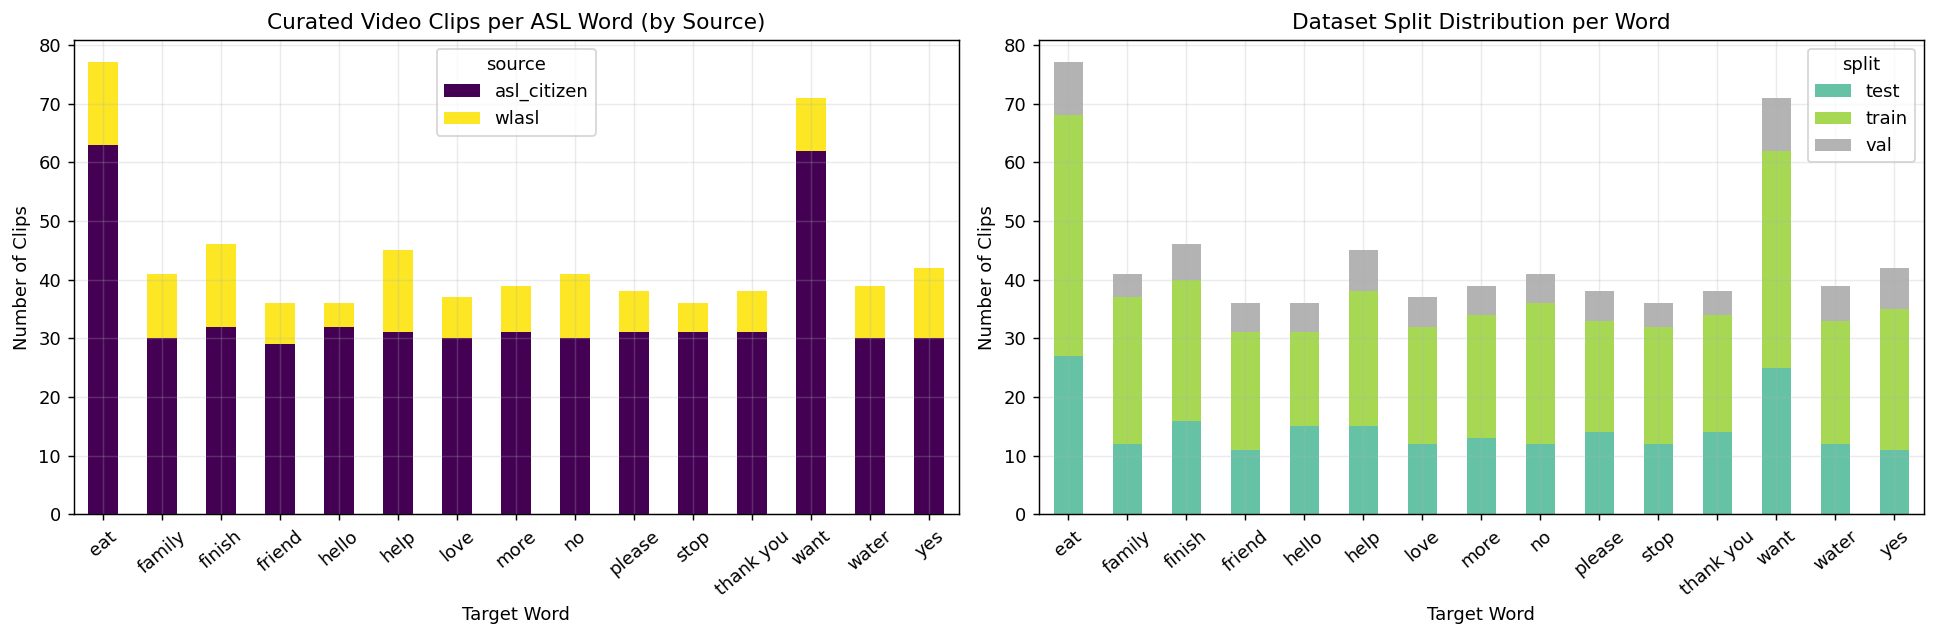

In [4]:
# @title 4. Figure 1: Dataset Exploratory Data Analysis (EDA)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

counts = manifest_df.groupby(["word", "source"]).size().unstack(fill_value=0).reindex(WORDS_15)
counts.plot(kind="bar", stacked=True, ax=axes[0], colormap="viridis")
axes[0].set_title("Curated Video Clips per ASL Word (by Source)")
axes[0].set_xlabel("Target Word")
axes[0].set_ylabel("Number of Clips")
axes[0].tick_params(axis="x", rotation=40)

split_counts = manifest_df.groupby(["word", "split"]).size().unstack(fill_value=0).reindex(WORDS_15)
split_counts.plot(kind="bar", stacked=True, ax=axes[1], colormap="Set2")
axes[1].set_title("Dataset Split Distribution per Word")
axes[1].set_xlabel("Target Word")
axes[1].set_ylabel("Number of Clips")
axes[1].tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_eda_dataset.png", dpi=300)
plt.show()


In [5]:
# @title 5. Extract & Cache MediaPipe Kinematic Sequences + 16x112x112 RGB Baseline Clips
CACHE_PATH = WORK_DIR / "word_features_cache_v1.npz"
RGB_FRAMES = 16
RGB_SIZE = 112

def process_video_clip(video_path: str):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return None
    frames = []
    while True:
        ok, frm = cap.read()
        if not ok or frm is None:
            break
        frames.append(frm)
    cap.release()
    if len(frames) < 6:
        return None
    if len(frames) > 96:
        idx = np.linspace(0, len(frames) - 1, 96, dtype=int)
        frames = [frames[i] for i in idx]

    static_list = []
    hand_hits = 0
    for frm in frames:
        rgb = cv2.cvtColor(frm, cv2.COLOR_BGR2RGB)
        mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        h_res = hand_detector.detect(mp_img)
        p_res = pose_detector.detect(mp_img)

        pose_arr = np.zeros((15, 3), dtype=np.float32)
        pose_ok = False
        if p_res and p_res.pose_landmarks:
            pose_arr = _lm_to_np(p_res.pose_landmarks[0])[POSE_INDICES]
            pose_ok = True

        lh_arr = np.zeros((21, 3), dtype=np.float32)
        rh_arr = np.zeros((21, 3), dtype=np.float32)
        lh_ok = False
        rh_ok = False
        if h_res and h_res.hand_landmarks:
            dets = []
            for j, lms in enumerate(h_res.hand_landmarks):
                pts = _lm_to_np(lms)
                lbl = h_res.handedness[j][0].category_name if (j < len(h_res.handedness) and h_res.handedness[j]) else "Right"
                sc = float(h_res.handedness[j][0].score) if (j < len(h_res.handedness) and h_res.handedness[j]) else 0.5
                dets.append((sc, lbl, pts))
            dets.sort(key=lambda x: x[0], reverse=True)
            for _, lbl, pts in dets:
                if lbl == "Left" and not lh_ok:
                    lh_arr, lh_ok = pts, True
                elif lbl == "Right" and not rh_ok:
                    rh_arr, rh_ok = pts, True
                elif not lh_ok:
                    lh_arr, lh_ok = pts, True
                elif not rh_ok:
                    rh_arr, rh_ok = pts, True

        if lh_ok or rh_ok:
            hand_hits += 1
        static_list.append(extract_word_static_from_arrays(pose_arr, lh_arr, rh_arr, pose_ok, lh_ok, rh_ok))

    if (hand_hits / len(frames)) < 0.18:
        return None

    # Uniform 48-frame static resample for lightweight caching + 16 RGB frames for Baseline 1
    static_arr = resample_sequence(np.stack(static_list, axis=0), target_len=WORD_SEQ_LEN)
    rgb_idx = np.linspace(0, len(frames) - 1, RGB_FRAMES, dtype=int)
    rgb_clip = np.stack([
        cv2.cvtColor(cv2.resize(frames[int(i)], (RGB_SIZE, RGB_SIZE)), cv2.COLOR_BGR2RGB)
        for i in rgb_idx
    ], axis=0).astype(np.uint8)
    return static_arr, rgb_clip

load_cache = False
if CACHE_PATH.exists():
    with np.load(CACHE_PATH, allow_pickle=True) as cached:
        if "manifest_len" in cached.files and int(cached["manifest_len"]) == len(manifest_df):
            static_seqs = cached["static_seqs"]
            rgb_clips = cached["rgb_clips"]
            labels = cached["labels"]
            splits = cached["splits"]
            signers = cached["signers"]
            sources = cached["sources"]
            load_cache = True
            print(f"Loaded cached features for {len(labels)} clips from Drive!")

if not load_cache:
    worker_script = Path("/content/mp_word_worker.py")
    worker_code = f'''
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

POSE_INDICES = {POSE_INDICES!r}
WORD_SEQ_LEN = {WORD_SEQ_LEN}
WORD_STATIC_DIM = {WORD_STATIC_DIM}
FINGER_ANGLE_TRIPLES = {FINGER_ANGLE_TRIPLES!r}
FINGERTIP_INDICES = {FINGERTIP_INDICES!r}
RGB_FRAMES = {RGB_FRAMES}
RGB_SIZE = {RGB_SIZE}

_HAND_DET = None
_POSE_DET = None

def init_worker(hand_path: str, pose_path: str):
    global _HAND_DET, _POSE_DET
    _HAND_DET = vision.HandLandmarker.create_from_options(
        vision.HandLandmarkerOptions(
            base_options=mp_python.BaseOptions(model_asset_path=hand_path),
            running_mode=vision.RunningMode.IMAGE,
            num_hands=2,
            min_hand_detection_confidence=0.40,
            min_hand_presence_confidence=0.40,
        )
    )
    _POSE_DET = vision.PoseLandmarker.create_from_options(
        vision.PoseLandmarkerOptions(
            base_options=mp_python.BaseOptions(model_asset_path=pose_path),
            running_mode=vision.RunningMode.IMAGE,
            num_poses=1,
            min_pose_detection_confidence=0.40,
            min_pose_presence_confidence=0.40,
        )
    )

def _lm_np(lms):
    arr = np.zeros((len(lms), 3), dtype=np.float32)
    for i, lm in enumerate(lms):
        arr[i] = (lm.x, lm.y, lm.z)
    return arr

def _angles(pts):
    if float(np.abs(pts).sum()) < 1e-6:
        return np.zeros(15, dtype=np.float32)
    out = np.zeros(15, dtype=np.float32)
    for i, (a, b, c) in enumerate(FINGER_ANGLE_TRIPLES):
        v1, v2 = pts[a] - pts[b], pts[c] - pts[b]
        out[i] = float(np.clip(np.dot(v1, v2) / (float(np.linalg.norm(v1) * np.linalg.norm(v2)) + 1e-6), -1.0, 1.0))
    return out

def _hand_local(pts, ok):
    if not ok or float(np.abs(pts).sum()) < 1e-6:
        return np.zeros((21, 3), dtype=np.float32)
    c = pts - pts[0:1]
    return (c / max(float(np.linalg.norm(c[9])), 0.02)).astype(np.float32)

def _resample(seq):
    t_len, dim = seq.shape
    if t_len == 0:
        return np.zeros((WORD_SEQ_LEN, dim), dtype=np.float32)
    if t_len == 1:
        return np.repeat(seq, WORD_SEQ_LEN, axis=0).astype(np.float32)
    if t_len == WORD_SEQ_LEN:
        return seq.astype(np.float32)
    pos = np.linspace(0.0, t_len - 1, WORD_SEQ_LEN, dtype=np.float32)
    idx0 = np.floor(pos).astype(np.int64)
    idx1 = np.minimum(idx0 + 1, t_len - 1)
    alpha = (pos - idx0)[:, None]
    return ((1.0 - alpha) * seq[idx0] + alpha * seq[idx1]).astype(np.float32)

def run_clip(task):
    idx, video_path = task
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return idx, None
    frames = []
    while True:
        ok, frm = cap.read()
        if not ok or frm is None:
            break
        frames.append(frm)
    cap.release()
    if len(frames) < 6:
        return idx, None
    if len(frames) > 96:
        frames = [frames[int(i)] for i in np.linspace(0, len(frames) - 1, 96, dtype=int)]
    static_list, hand_hits = [], 0
    for frm in frames:
        rgb = cv2.cvtColor(frm, cv2.COLOR_BGR2RGB)
        mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        h_res = _HAND_DET.detect(mp_img)
        p_res = _POSE_DET.detect(mp_img)
        pose_arr = np.zeros((15, 3), dtype=np.float32)
        pose_ok = False
        if p_res and p_res.pose_landmarks:
            pose_arr = _lm_np(p_res.pose_landmarks[0])[POSE_INDICES]
            pose_ok = True
        lh_arr, rh_arr = np.zeros((21, 3), dtype=np.float32), np.zeros((21, 3), dtype=np.float32)
        lh_ok, rh_ok = False, False
        if h_res and h_res.hand_landmarks:
            dets = []
            for j, lms in enumerate(h_res.hand_landmarks):
                pts = _lm_np(lms)
                lbl = h_res.handedness[j][0].category_name if (j < len(h_res.handedness) and h_res.handedness[j]) else "Right"
                sc = float(h_res.handedness[j][0].score) if (j < len(h_res.handedness) and h_res.handedness[j]) else 0.5
                dets.append((sc, lbl, pts))
            dets.sort(key=lambda x: x[0], reverse=True)
            for _, lbl, pts in dets:
                if lbl == "Left" and not lh_ok:
                    lh_arr, lh_ok = pts, True
                elif lbl == "Right" and not rh_ok:
                    rh_arr, rh_ok = pts, True
                elif not lh_ok:
                    lh_arr, lh_ok = pts, True
                elif not rh_ok:
                    rh_arr, rh_ok = pts, True
        if lh_ok or rh_ok:
            hand_hits += 1
        if pose_ok:
            anchor = 0.5 * (pose_arr[7] + pose_arr[8])
            scale = max(float(np.linalg.norm(pose_arr[7, :2] - pose_arr[8, :2])), 0.15)
            pose_norm = ((pose_arr - anchor) / scale).astype(np.float32)
        else:
            anchor, scale = np.array([0.5, 0.5, 0.0], dtype=np.float32), 0.25
            pose_norm = np.zeros((15, 3), dtype=np.float32)
        lh_norm = ((lh_arr - anchor) / scale).astype(np.float32) if lh_ok else np.zeros((21, 3), dtype=np.float32)
        rh_norm = ((rh_arr - anchor) / scale).astype(np.float32) if rh_ok else np.zeros((21, 3), dtype=np.float32)
        pos_torso = np.concatenate([pose_norm, lh_norm, rh_norm], axis=0).reshape(-1)
        lh_l, rh_l = _hand_local(lh_arr, lh_ok), _hand_local(rh_arr, rh_ok)
        lh_a = _angles(lh_arr) if lh_ok else np.zeros(15, dtype=np.float32)
        rh_a = _angles(rh_arr) if rh_ok else np.zeros(15, dtype=np.float32)
        rd = np.zeros(16, dtype=np.float32)
        if lh_ok:
            for k, tip in enumerate(FINGERTIP_INDICES):
                rd[k] = float(np.linalg.norm(lh_l[tip]))
        if rh_ok:
            for k, tip in enumerate(FINGERTIP_INDICES):
                rd[5 + k] = float(np.linalg.norm(rh_l[tip]))
        if pose_ok:
            nose, mouth_mid = pose_norm[0], 0.5 * (pose_norm[5] + pose_norm[6])
            if lh_ok:
                rd[10], rd[11] = float(np.linalg.norm(lh_norm[0] - nose)), float(np.linalg.norm(lh_norm[0] - mouth_mid))
            if rh_ok:
                rd[12], rd[13] = float(np.linalg.norm(rh_norm[0] - nose)), float(np.linalg.norm(rh_norm[0] - mouth_mid))
        if lh_ok and rh_ok:
            rd[14], rd[15] = float(np.linalg.norm(lh_norm[0] - rh_norm[0])), float(np.linalg.norm(lh_norm[8] - rh_norm[8]))
        pres = np.array([float(pose_ok), float(lh_ok), float(rh_ok)], dtype=np.float32)
        static_list.append(np.concatenate([pos_torso, lh_l.reshape(-1), rh_l.reshape(-1), lh_a, rh_a, rd, pres], axis=0).astype(np.float32))
    if (hand_hits / len(frames)) < 0.18:
        return idx, None
    static_arr = _resample(np.stack(static_list, axis=0))
    rgb_idx = np.linspace(0, len(frames) - 1, RGB_FRAMES, dtype=int)
    rgb_clip = np.stack([cv2.cvtColor(cv2.resize(frames[int(i)], (RGB_SIZE, RGB_SIZE)), cv2.COLOR_BGR2RGB) for i in rgb_idx], axis=0).astype(np.uint8)
    return idx, (static_arr, rgb_clip)
'''
    worker_script.write_text(worker_code, encoding="utf-8")
    import sys
    if "/content" not in sys.path:
        sys.path.insert(0, "/content")
    import mp_word_worker

    tasks = list(enumerate(manifest_df["clip_path"].tolist()))
    results_map = {}
    if EXTRACTION_WORKERS > 1:
        try:
            ctx = multiprocessing.get_context("spawn")
            with ProcessPoolExecutor(
                max_workers=EXTRACTION_WORKERS,
                mp_context=ctx,
                initializer=mp_word_worker.init_worker,
                initargs=(str(MP_ASSETS_DIR / "hand_landmarker.task"), str(MP_ASSETS_DIR / "pose_landmarker_lite.task")),
            ) as pool:
                for idx, out in tqdm(pool.map(mp_word_worker.run_clip, tasks, chunksize=4), total=len(tasks), desc=f"Extracting ({EXTRACTION_WORKERS} workers)"):
                    if out is not None:
                        results_map[idx] = out
        except Exception as exc:
            print("Parallel extraction fallback to single-process:", exc)
            results_map = {}

    if not results_map:
        for idx, vp in tqdm(tasks, total=len(tasks), desc="Extracting Landmarks"):
            out = process_video_clip(vp)
            if out is not None:
                results_map[idx] = out

    s_list, r_list, y_list, sp_list, sg_list, src_list = [], [], [], [], [], []
    for idx in sorted(results_map.keys()):
        st, rc = results_map[idx]
        row = manifest_df.iloc[idx]
        s_list.append(st)
        r_list.append(rc)
        y_list.append(int(row["label_id"]))
        sp_list.append(str(row["split"]))
        sg_list.append(str(row["signer_id"]))
        src_list.append(str(row["source"]))

    static_seqs = np.stack(s_list, axis=0).astype(np.float32)
    rgb_clips = np.stack(r_list, axis=0).astype(np.uint8)
    labels = np.array(y_list, dtype=np.int64)
    splits = np.array(sp_list)
    signers = np.array(sg_list)
    sources = np.array(src_list)
    np.savez_compressed(
        CACHE_PATH,
        manifest_len=len(manifest_df),
        static_seqs=static_seqs,
        rgb_clips=rgb_clips,
        labels=labels,
        splits=splits,
        signers=signers,
        sources=sources,
    )
    print(f"Extracted & cached {len(labels)} clean clips ({len(manifest_df) - len(labels)} noisy clips filtered).")

ram_mb = (static_seqs.nbytes + rgb_clips.nbytes) / 1e6
print(f"In-RAM cache -> Static: {static_seqs.shape} | RGB: {rgb_clips.shape} | RAM used: {ram_mb:.1f} MB / {TOTAL_RAM_GB:.1f} GB total")


Extracting (8 workers):   0%|          | 0/662 [00:00<?, ?it/s]

Extracted & cached 653 clean clips (9 noisy clips filtered).
In-RAM cache -> Static: (653, 48, 346) | RGB: (653, 16, 112, 112, 3) | RAM used: 436.6 MB / 56.9 GB total


In [6]:
# @title 6. Signer-Disjoint Data Split, Domain-Invariant Augmentations & PyTorch Datasets
from sklearn.model_selection import GroupShuffleSplit

# Ensure balanced val/test splits when official splits are small or missing
train_mask = (splits == "train")
val_mask = (splits == "val")
test_mask = (splits == "test")

if val_mask.sum() < 30 or test_mask.sum() < 30:
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
    tr_idx, tmp_idx = next(gss1.split(static_seqs, labels, groups=signers))
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
    v_sub, te_sub = next(gss2.split(static_seqs[tmp_idx], labels[tmp_idx], groups=signers[tmp_idx]))
    val_idx, test_idx = tmp_idx[v_sub], tmp_idx[te_sub]
    train_idx = tr_idx
else:
    train_idx = np.where(train_mask)[0]
    val_idx = np.where(val_mask)[0]
    test_idx = np.where(test_mask)[0]

# Oversample personal calibration clips in train if present
cal_train = [i for i in train_idx if sources[i] == "calibration"]
if cal_train:
    train_idx = np.concatenate([train_idx] + [np.array(cal_train)] * 3)

print(f"Split sizes -> Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

def mirror_static_sequence(seq: np.ndarray) -> np.ndarray:
    """Exact horizontal mirror (flip x and swap Left/Right anatomy) on (T, 346) sequence."""
    out = seq.copy()
    t = out.shape[0]

    # 1) Torso-normalized coordinates (0:171)
    pose = out[:, 0:45].reshape(t, 15, 3)
    pose[:, :, 0] *= -1.0
    pose = pose[:, POSE_SWAP_PERM, :]

    lh_t = out[:, 45:108].reshape(t, 21, 3).copy()
    rh_t = out[:, 108:171].reshape(t, 21, 3).copy()
    lh_t[:, :, 0] *= -1.0
    rh_t[:, :, 0] *= -1.0
    out[:, 0:45] = pose.reshape(t, 45)
    out[:, 45:108] = rh_t.reshape(t, 63)
    out[:, 108:171] = lh_t.reshape(t, 63)

    # 2) Hand-local coordinates (171:297)
    lh_l = out[:, 171:234].reshape(t, 21, 3).copy()
    rh_l = out[:, 234:297].reshape(t, 21, 3).copy()
    lh_l[:, :, 0] *= -1.0
    rh_l[:, :, 0] *= -1.0
    out[:, 171:234] = rh_l.reshape(t, 63)
    out[:, 234:297] = lh_l.reshape(t, 63)

    # 3) Angles (297:327)
    lh_a = out[:, 297:312].copy()
    rh_a = out[:, 312:327].copy()
    out[:, 297:312] = rh_a
    out[:, 312:327] = lh_a

    # 4) Relational distances (327:343)
    rd = out[:, 327:343].copy()
    out[:, 327:332] = rd[:, 5:10]
    out[:, 332:337] = rd[:, 0:5]
    out[:, 337:339] = rd[:, 12:14]
    out[:, 339:341] = rd[:, 10:12]

    # 5) Presence flags (343:346)
    pr = out[:, 343:346].copy()
    out[:, 344] = pr[:, 2]
    out[:, 345] = pr[:, 1]
    return out

def augment_static_sequence(seq: np.ndarray) -> np.ndarray:
    out = seq.copy()
    if random.random() < 0.50:
        out = mirror_static_sequence(out)

    # Temporal crop / speed warp
    if random.random() < 0.70:
        t = out.shape[0]
        start = random.randint(0, 4)
        end = t - random.randint(0, 4)
        if end - start >= 24:
            out = resample_sequence(out[start:end], WORD_SEQ_LEN)

    # Global scale + small 2D camera tilt + Gaussian landmark noise
    if random.random() < 0.75:
        scale = random.uniform(0.90, 1.12)
        theta = np.deg2rad(random.uniform(-8.0, 8.0))
        c, s = np.cos(theta), np.sin(theta)
        pts_torso = out[:, :171].reshape(WORD_SEQ_LEN, 57, 3)
        x_new = (pts_torso[:, :, 0] * c - pts_torso[:, :, 1] * s) * scale
        y_new = (pts_torso[:, :, 0] * s + pts_torso[:, :, 1] * c) * scale
        pts_torso[:, :, 0] = x_new
        pts_torso[:, :, 1] = y_new
        out[:, :171] = pts_torso.reshape(WORD_SEQ_LEN, 171)

    if random.random() < 0.65:
        out[:, :297] += np.random.normal(0.0, 0.008, size=(WORD_SEQ_LEN, 297)).astype(np.float32)

    return out

class WordKinematicDataset(Dataset):
    def __init__(self, indices, augment: bool = False):
        self.indices = indices
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        i = int(self.indices[idx])
        st = static_seqs[i]
        if self.augment:
            st = augment_static_sequence(st)
        feat = static_to_kinematic_688(st, target_len=WORD_SEQ_LEN)
        return torch.from_numpy(feat), torch.tensor(labels[i], dtype=torch.long)

class WordRgbDataset(Dataset):
    def __init__(self, indices, augment: bool = False):
        self.indices = indices
        self.augment = augment
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        i = int(self.indices[idx])
        clip = rgb_clips[i]  # (16, 112, 112, 3) uint8
        if self.augment and random.random() < 0.5:
            clip = clip[:, :, ::-1, :].copy()
        x = torch.from_numpy(clip).permute(0, 3, 1, 2).float() / 255.0
        if self.augment:
            gain = random.uniform(0.85, 1.15)
            x = torch.clamp(x * gain, 0.0, 1.0)
        x = (x - self.mean) / self.std
        return x, torch.tensor(labels[i], dtype=torch.long)

# Precompute non-augmented Val & Test 688-dim tensors directly in RAM for zero-overhead evaluation
val_kin_x = torch.from_numpy(np.stack([static_to_kinematic_688(static_seqs[i], WORD_SEQ_LEN) for i in val_idx], axis=0))
val_kin_y = torch.from_numpy(labels[val_idx]).long()
test_kin_x = torch.from_numpy(np.stack([static_to_kinematic_688(static_seqs[i], WORD_SEQ_LEN) for i in test_idx], axis=0))
test_kin_y = torch.from_numpy(labels[test_idx]).long()

train_kin_ds = WordKinematicDataset(train_idx, augment=True)
train_kin_loader = DataLoader(
    train_kin_ds,
    batch_size=KIN_BATCH_SIZE,
    shuffle=True,
    num_workers=LOADER_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
)
val_kin_loader = DataLoader(TensorDataset(val_kin_x, val_kin_y), batch_size=KIN_BATCH_SIZE, shuffle=False, pin_memory=True)
test_kin_loader = DataLoader(TensorDataset(test_kin_x, test_kin_y), batch_size=KIN_BATCH_SIZE, shuffle=False, pin_memory=True)

train_rgb_loader = DataLoader(
    WordRgbDataset(train_idx, augment=True),
    batch_size=RGB_BATCH_SIZE,
    shuffle=True,
    num_workers=LOADER_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
)
val_rgb_loader = DataLoader(WordRgbDataset(val_idx, augment=False), batch_size=RGB_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_rgb_loader = DataLoader(WordRgbDataset(test_idx, augment=False), batch_size=RGB_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


Split sizes -> Train: 352 | Val: 84 | Test: 217


In [7]:
# @title 7. Define 3 Academic Architectures (RGB Baseline, Pose BiGRU Baseline, Kinematic Conformer)
import torchvision.models as tv_models

class RgbVideoBaseline(nn.Module):
    def __init__(self, num_classes: int = 15):
        super().__init__()
        backbone = tv_models.resnet18(weights=tv_models.ResNet18_Weights.DEFAULT)
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])
        self.gru = nn.GRU(512, 128, num_layers=1, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward(self, x):
        b, t, c, h, w = x.shape
        feats = self.encoder(x.view(b * t, c, h, w)).view(b, t, 512)
        out, _ = self.gru(feats)
        pooled = out.mean(dim=1)
        return self.head(pooled)

class PoseBiGRUBaseline(nn.Module):
    def __init__(self, in_dim: int = 171, num_classes: int = 15):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(in_dim, 160), nn.LayerNorm(160), nn.GELU())
        self.gru = nn.GRU(160, 160, num_layers=2, batch_first=True, bidirectional=True, dropout=0.25)
        self.head = nn.Sequential(nn.LayerNorm(320), nn.Dropout(0.3), nn.Linear(320, num_classes))

    def forward(self, x):
        x_pos = x[:, :, :171]
        h, _ = self.gru(self.proj(x_pos))
        pooled = h.mean(dim=1)
        return self.head(pooled)

class ExplicitMultiHeadSelfAttention(nn.Module):
    """ONNX-friendly Multi-Head Self-Attention using pure matrix ops."""
    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.2):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(d_model, d_model * 3)
        self.proj = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        b, t, c = x.shape
        qkv = self.qkv(x).view(b, t, 3, self.n_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = torch.softmax(torch.matmul(q, k.transpose(-2, -1)) * self.scale, dim=-1)
        out = torch.matmul(self.drop(attn), v).transpose(1, 2).contiguous().view(b, t, c)
        return self.proj(out)

class ConformerBlock(nn.Module):
    def __init__(self, d_model: int = 192, n_heads: int = 4, conv_kernel: int = 7, dropout: float = 0.2):
        super().__init__()
        self.ff1 = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model * 2, d_model),
            nn.Dropout(dropout),
        )
        self.attn_norm = nn.LayerNorm(d_model)
        self.attn = ExplicitMultiHeadSelfAttention(d_model, n_heads, dropout=dropout)
        self.attn_drop = nn.Dropout(dropout)

        self.conv_norm = nn.LayerNorm(d_model)
        self.pw1 = nn.Conv1d(d_model, d_model * 2, kernel_size=1)
        self.dw = nn.Conv1d(d_model, d_model, kernel_size=conv_kernel, padding=conv_kernel // 2, groups=d_model)
        self.bn = nn.BatchNorm1d(d_model)
        self.pw2 = nn.Conv1d(d_model, d_model, kernel_size=1)
        self.conv_drop = nn.Dropout(dropout)

        self.ff2 = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model * 2, d_model),
            nn.Dropout(dropout),
        )
        self.final_norm = nn.LayerNorm(d_model)

    def forward(self, x):
        x = x + 0.5 * self.ff1(x)
        x = x + self.attn_drop(self.attn(self.attn_norm(x)))

        c = self.conv_norm(x).transpose(1, 2)
        a, b_gate = self.pw1(c).chunk(2, dim=1)
        c = a * torch.sigmoid(b_gate)
        c = F.silu(self.bn(self.dw(c)))
        c = self.conv_drop(self.pw2(c)).transpose(1, 2)
        x = x + c

        x = x + 0.5 * self.ff2(x)
        return self.final_norm(x)

class WordConformer(nn.Module):
    def __init__(self, in_dim: int = WORD_FEATURE_DIM, d_model: int = 192, n_layers: int = 4, num_classes: int = 15):
        super().__init__()
        self.input_proj = nn.Sequential(
            nn.Linear(in_dim, d_model),
            nn.LayerNorm(d_model),
            nn.GELU(),
            nn.Dropout(0.15),
        )
        self.pos_emb = nn.Parameter(torch.randn(1, WORD_SEQ_LEN, d_model) * 0.02)
        self.blocks = nn.ModuleList([ConformerBlock(d_model=d_model) for _ in range(n_layers)])
        self.attn_pool = nn.Sequential(nn.Linear(d_model, d_model // 2), nn.Tanh(), nn.Linear(d_model // 2, 1))
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Dropout(0.25), nn.Linear(d_model, num_classes))

    def forward(self, x, return_details: bool = False):
        h = self.input_proj(x) + self.pos_emb
        for blk in self.blocks:
            h = blk(h)
        weights = torch.softmax(self.attn_pool(h).squeeze(-1), dim=1)  # (B, T)
        emb = torch.sum(h * weights.unsqueeze(-1), dim=1)               # (B, d_model)
        logits = self.head(emb)
        if return_details:
            return logits, weights, emb
        return logits

print("Conformer params:", sum(p.numel() for p in WordConformer().parameters()) // 1000, "K")


Conformer params: 2400 K


In [8]:
# @title 8. Training Engine & 3-Way Academic Model Benchmark
from copy import deepcopy
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

def evaluate_model(model, loader, is_conformer: bool = False):
    model.eval()
    all_logits, all_y = [], []
    t0 = time.perf_counter()
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            all_logits.append(logits.cpu().numpy())
            all_y.append(yb.numpy())
    elapsed_ms = ((time.perf_counter() - t0) / max(len(loader.dataset), 1)) * 1000.0
    logits_np = np.concatenate(all_logits, axis=0)
    y_true = np.concatenate(all_y, axis=0)
    probs = torch.softmax(torch.from_numpy(logits_np), dim=-1).numpy()
    preds = np.argmax(probs, axis=1)
    return {
        "top1": accuracy_score(y_true, preds),
        "top3": top_k_accuracy_score(y_true, probs, k=3, labels=list(range(len(WORDS_15)))),
        "macro_f1": f1_score(y_true, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, preds, average="weighted", zero_division=0),
        "latency_ms": elapsed_ms,
        "y_true": y_true,
        "y_pred": preds,
        "probs": probs,
    }

def train_loop(model, train_loader, val_loader, epochs: int, lr: float, name: str, use_mixup: bool = False, use_ema: bool = False):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=2e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=lr * 0.02)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.10)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

    ema_model = deepcopy(model) if use_ema else None
    best_f1 = -1.0
    best_state = deepcopy(model.state_dict())
    history = {"train_loss": [], "val_acc": [], "val_f1": []}

    for ep in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                if use_mixup and random.random() < 0.45 and xb.size(0) > 1:
                    lam = float(np.random.beta(0.3, 0.3))
                    perm = torch.randperm(xb.size(0), device=DEVICE)
                    xb_mix = lam * xb + (1.0 - lam) * xb[perm]
                    logits = model(xb_mix)
                    loss = lam * criterion(logits, yb) + (1.0 - lam) * criterion(logits, yb[perm])
                else:
                    logits = model(xb)
                    loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.5)
            scaler.step(optimizer)
            scaler.update()
            total_loss += float(loss.item()) * xb.size(0)

            if ema_model is not None:
                with torch.no_grad():
                    for p_ema, p_cur in zip(ema_model.parameters(), model.parameters()):
                        p_ema.data.mul_(0.992).add_(p_cur.data, alpha=0.008)

        scheduler.step()
        eval_net = ema_model if ema_model is not None else model
        val_m = evaluate_model(eval_net, val_loader)
        tr_loss = total_loss / max(len(train_loader.dataset), 1)
        history["train_loss"].append(tr_loss)
        history["val_acc"].append(val_m["top1"])
        history["val_f1"].append(val_m["macro_f1"])

        if val_m["macro_f1"] > best_f1:
            best_f1 = val_m["macro_f1"]
            best_state = deepcopy(eval_net.state_dict())

        if ep in (1, epochs) or ep % max(1, epochs // 5) == 0:
            print(f"[{name}] Ep {ep:02d}/{epochs} | Loss {tr_loss:.4f} | Val Acc {val_m['top1']*100:.1f}% | Val F1 {val_m['macro_f1']*100:.1f}%")

    model.load_state_dict(best_state)
    torch.save(best_state, WORK_DIR / f"{name}_best.pt")
    return model, history

print("=== Training Baseline 1: RGB ResNet-18 + BiGRU ===")
rgb_model, hist_rgb = train_loop(RgbVideoBaseline(len(WORDS_15)), train_rgb_loader, val_rgb_loader, epochs=12, lr=3e-4, name="rgb_baseline")

print("\n=== Training Baseline 2: Pose-Only BiGRU ===")
gru_model, hist_gru = train_loop(PoseBiGRUBaseline(171, len(WORDS_15)), train_kin_loader, val_kin_loader, epochs=35, lr=1e-3, name="pose_bigru")

print("\n=== Training Proposed Model: Kinematic Conformer (688-dim + EMA + Mixup) ===")
conformer_model, hist_conf = train_loop(WordConformer(WORD_FEATURE_DIM, 192, 4, len(WORDS_15)), train_kin_loader, val_kin_loader, epochs=55, lr=9e-4, name="kinematic_conformer", use_mixup=True, use_ema=True)

res_rgb = evaluate_model(rgb_model, test_rgb_loader)
res_gru = evaluate_model(gru_model, test_kin_loader)
res_conf = evaluate_model(conformer_model, test_kin_loader)

bench_df = pd.DataFrame([
    {"Model": "Baseline 1: RGB ResNet18 + BiGRU", "Top-1 Acc (%)": res_rgb["top1"]*100, "Top-3 Acc (%)": res_rgb["top3"]*100, "Macro F1 (%)": res_rgb["macro_f1"]*100, "Weighted F1 (%)": res_rgb["weighted_f1"]*100, "Params (M)": sum(p.numel() for p in rgb_model.parameters())/1e6},
    {"Model": "Baseline 2: Pose-Only BiGRU (171d)", "Top-1 Acc (%)": res_gru["top1"]*100, "Top-3 Acc (%)": res_gru["top3"]*100, "Macro F1 (%)": res_gru["macro_f1"]*100, "Weighted F1 (%)": res_gru["weighted_f1"]*100, "Params (M)": sum(p.numel() for p in gru_model.parameters())/1e6},
    {"Model": "Proposed: Kinematic Conformer (688d)", "Top-1 Acc (%)": res_conf["top1"]*100, "Top-3 Acc (%)": res_conf["top3"]*100, "Macro F1 (%)": res_conf["macro_f1"]*100, "Weighted F1 (%)": res_conf["weighted_f1"]*100, "Params (M)": sum(p.numel() for p in conformer_model.parameters())/1e6},
])
bench_df.to_csv(WORK_DIR / "benchmark_results.csv", index=False)
display(bench_df.round(2))


=== Training Baseline 1: RGB ResNet-18 + BiGRU ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 240MB/s]


[rgb_baseline] Ep 01/12 | Loss 2.8279 | Val Acc 11.9% | Val F1 4.9%
[rgb_baseline] Ep 02/12 | Loss 2.3612 | Val Acc 14.3% | Val F1 7.6%
[rgb_baseline] Ep 04/12 | Loss 1.7209 | Val Acc 17.9% | Val F1 13.0%
[rgb_baseline] Ep 06/12 | Loss 1.1644 | Val Acc 23.8% | Val F1 21.8%
[rgb_baseline] Ep 08/12 | Loss 0.9027 | Val Acc 25.0% | Val F1 22.8%
[rgb_baseline] Ep 10/12 | Loss 0.7548 | Val Acc 25.0% | Val F1 22.9%
[rgb_baseline] Ep 12/12 | Loss 0.7009 | Val Acc 25.0% | Val F1 22.8%

=== Training Baseline 2: Pose-Only BiGRU ===
[pose_bigru] Ep 01/35 | Loss 2.9724 | Val Acc 11.9% | Val F1 8.4%
[pose_bigru] Ep 07/35 | Loss 1.4817 | Val Acc 72.6% | Val F1 70.0%
[pose_bigru] Ep 14/35 | Loss 1.0106 | Val Acc 88.1% | Val F1 86.3%
[pose_bigru] Ep 21/35 | Loss 0.8015 | Val Acc 94.0% | Val F1 93.4%
[pose_bigru] Ep 28/35 | Loss 0.7204 | Val Acc 96.4% | Val F1 96.3%
[pose_bigru] Ep 35/35 | Loss 0.6889 | Val Acc 96.4% | Val F1 96.0%

=== Training Proposed Model: Kinematic Conformer (688-dim + EMA + Mixup

,Model,Top-1 Acc (%),Top-3 Acc (%),Macro F1 (%),Weighted F1 (%),Params (M)
0,Baseline 1: RGB ResNet18 + BiGRU,34.56,55.30,29.85,31.92,11.67
1,Baseline 2: Pose-Only BiGRU (171d),93.09,99.54,92.99,93.04,0.81
2,Proposed: Kinematic Conformer (688d),90.78,98.62,91.04,90.65,2.40


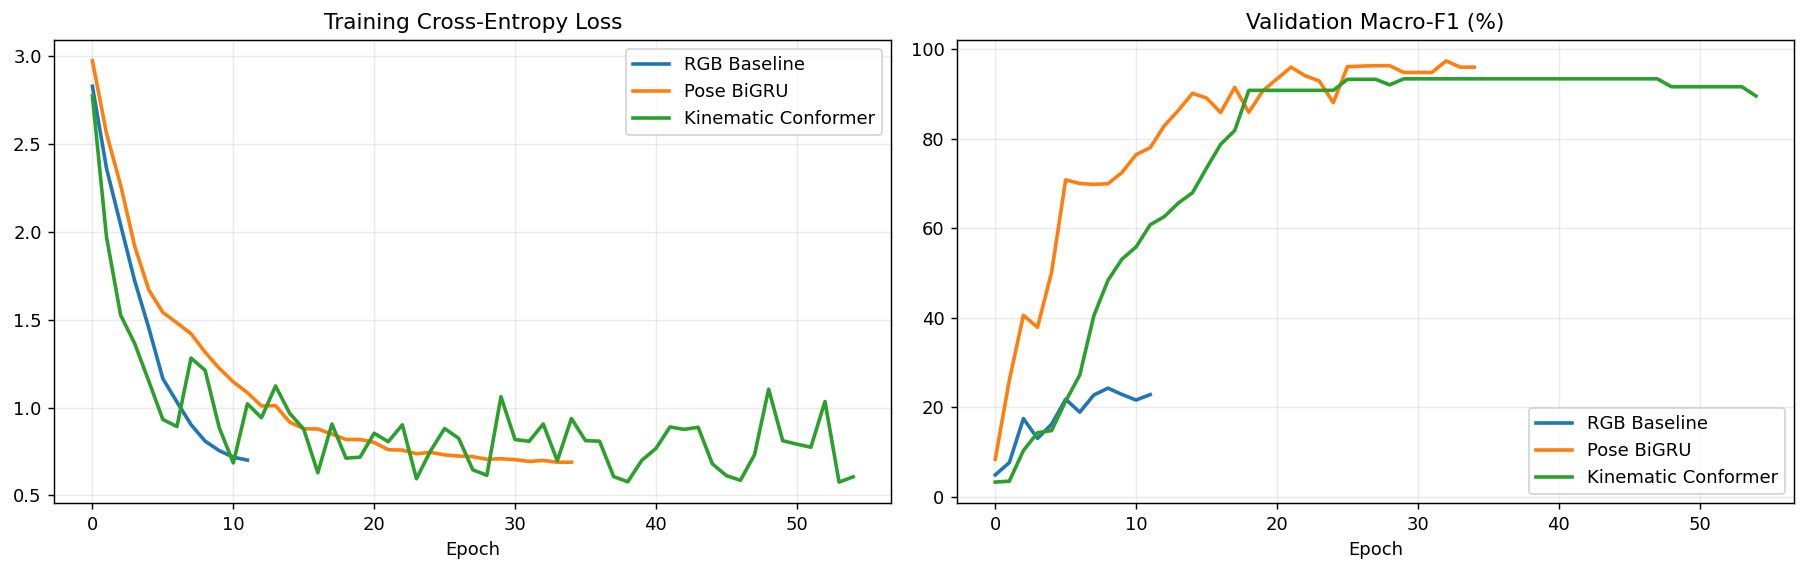

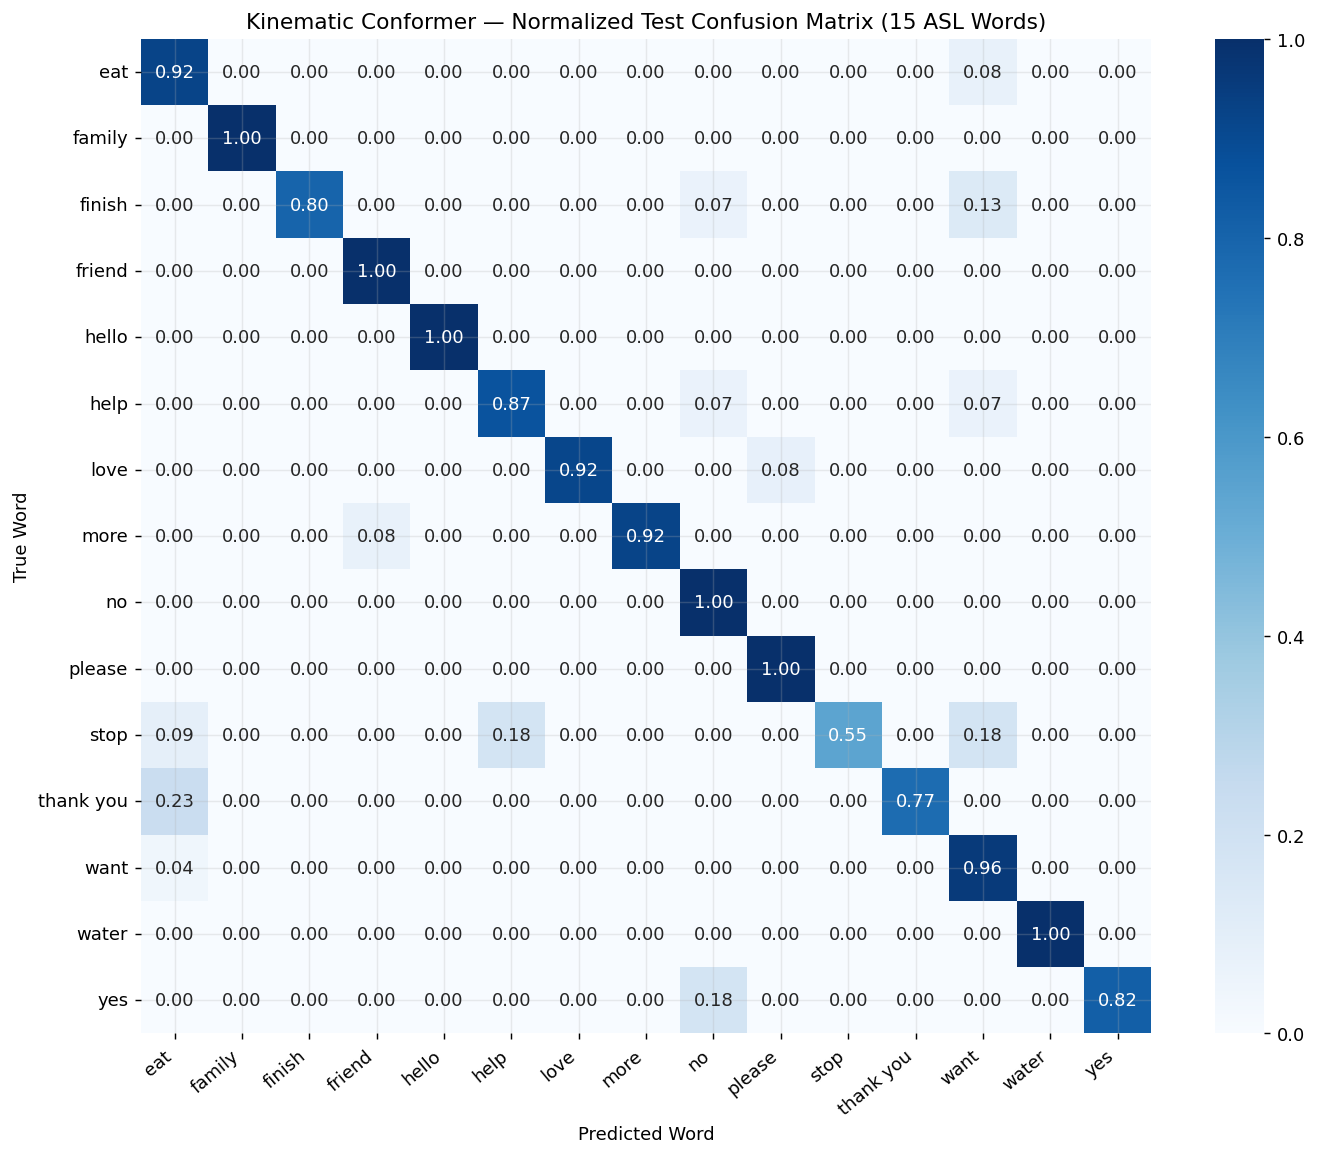

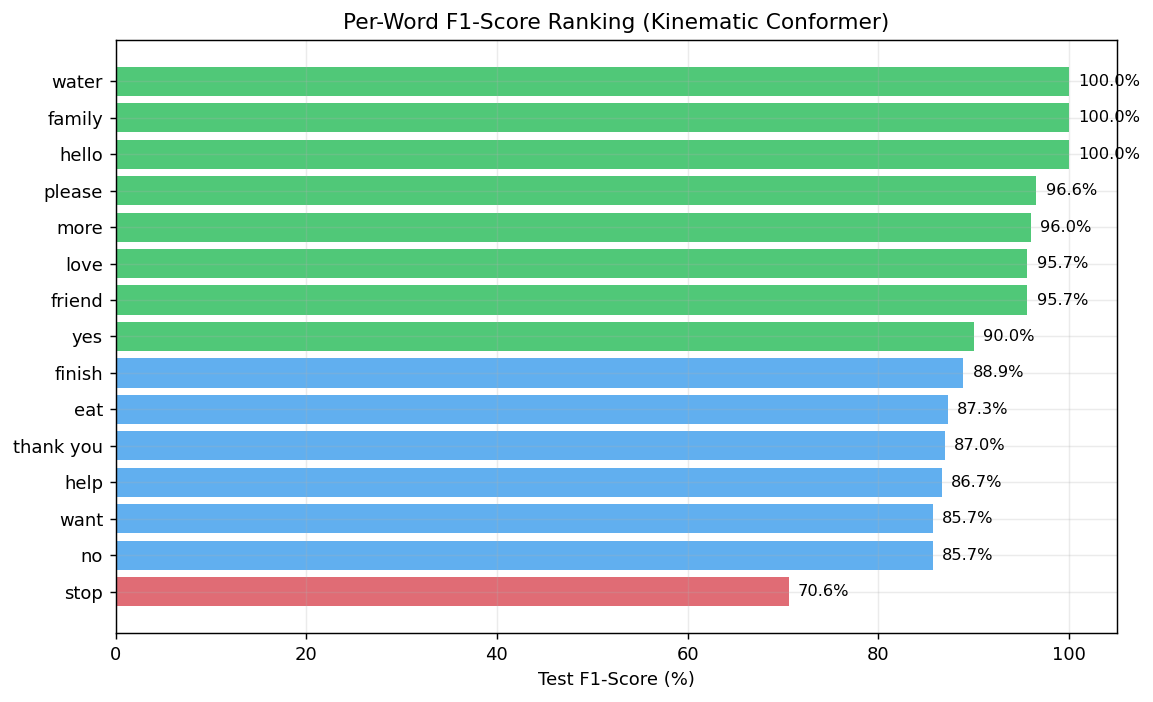

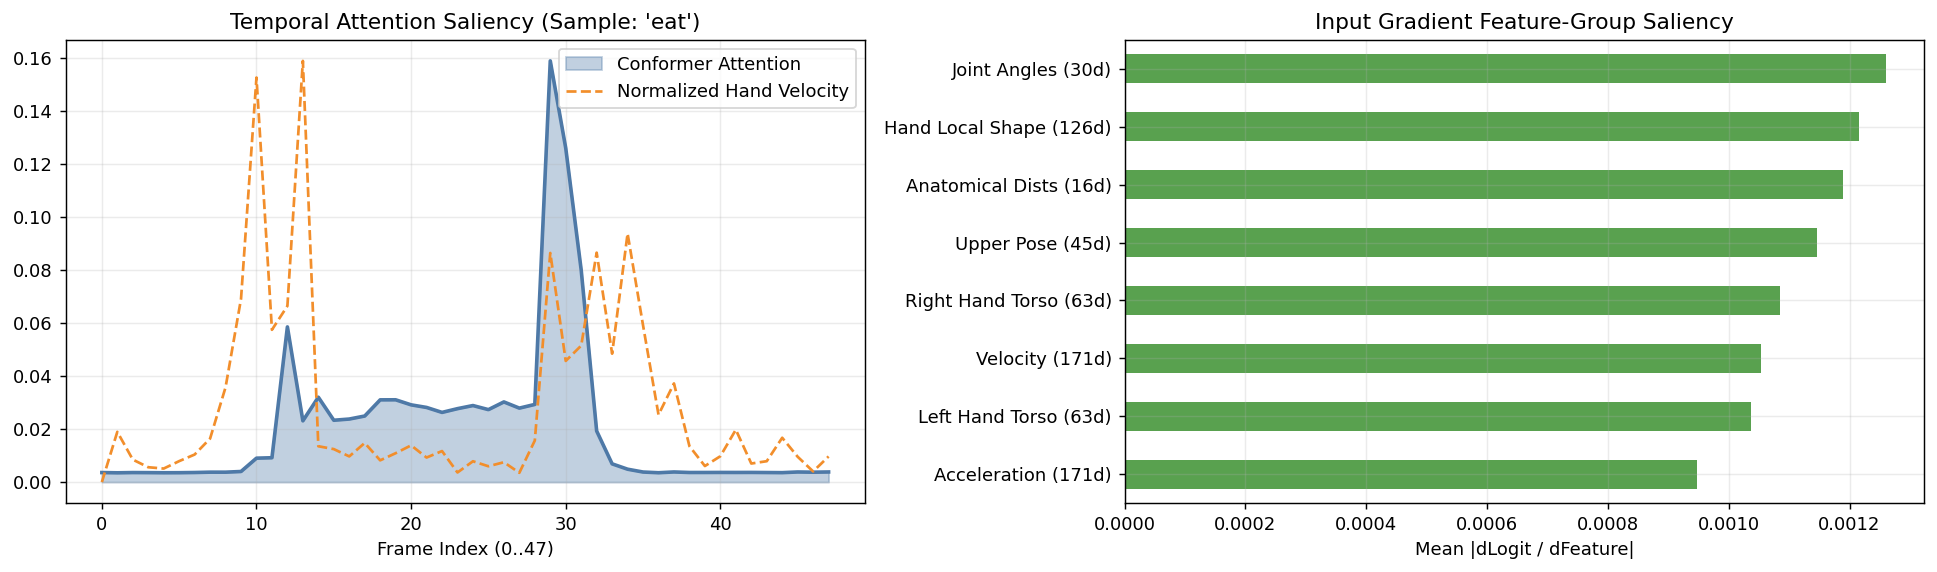

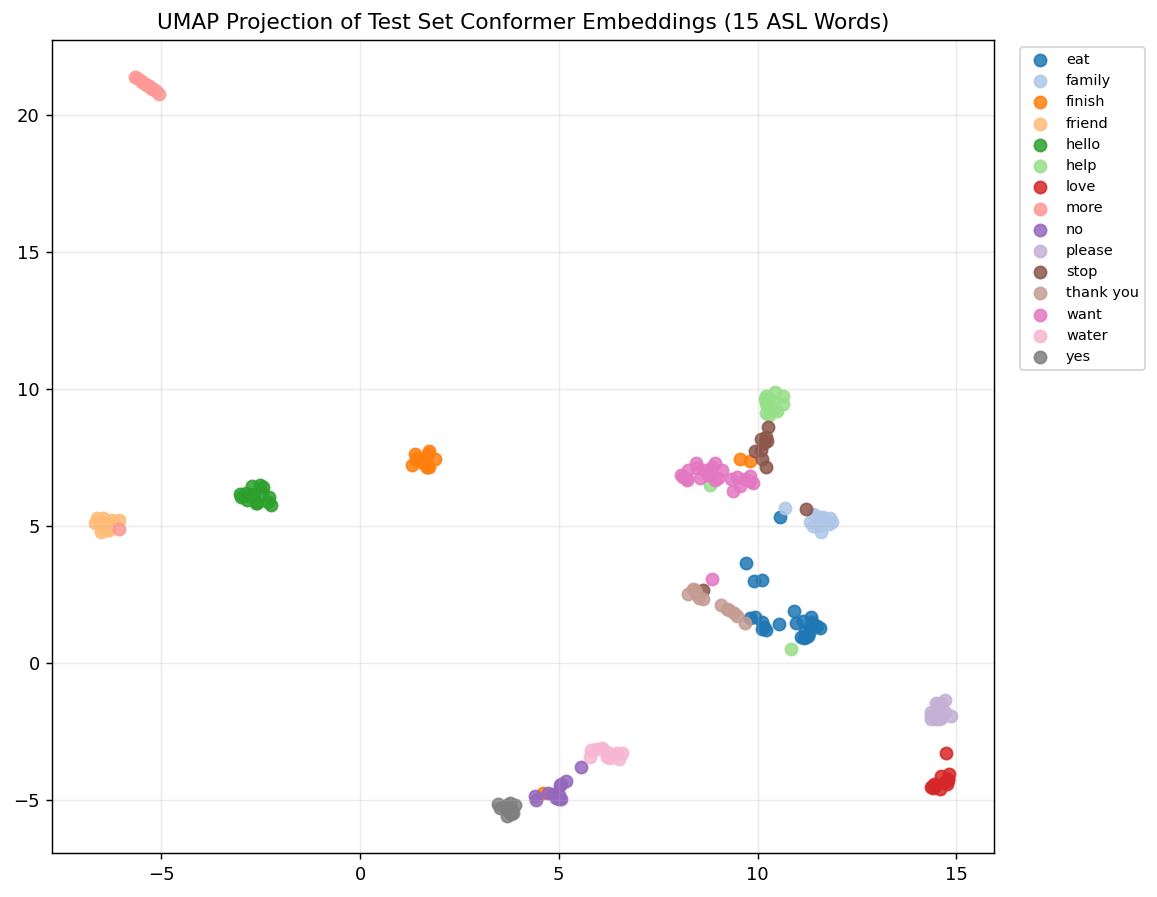

Total Test Misclassifications: 20 / 217


,True,Predicted,Conf (%),True Prob (%)
0,eat,want,20.1,15.9
1,eat,want,26.9,23.8
2,finish,want,35.5,10.0
3,finish,want,30.4,16.5
4,help,want,37.0,29.0
5,help,no,40.8,4.2
6,love,please,29.8,26.8
7,stop,eat,36.0,3.0
8,stop,help,24.4,21.4
9,stop,want,21.9,10.8


In [9]:
# @title 9. Academic Visualizations (Training Curves, Confusion Matrix, F1 Ranking, Attention Saliency, UMAP, Failure Cases)
from sklearn.metrics import confusion_matrix, classification_report
import umap

# Fig 2: Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for lbl, hist in [("RGB Baseline", hist_rgb), ("Pose BiGRU", hist_gru), ("Kinematic Conformer", hist_conf)]:
    axes[0].plot(hist["train_loss"], label=lbl, linewidth=2)
    axes[1].plot([v * 100 for v in hist["val_f1"]], label=lbl, linewidth=2)
axes[0].set_title("Training Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].set_title("Validation Macro-F1 (%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_training_dynamics.png", dpi=300)
plt.show()

# Fig 3: Confusion Matrix
cm = confusion_matrix(res_conf["y_true"], res_conf["y_pred"], labels=list(range(len(WORDS_15))), normalize="true")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=WORDS_15, yticklabels=WORDS_15, ax=ax)
ax.set_title("Kinematic Conformer — Normalized Test Confusion Matrix (15 ASL Words)")
ax.set_xlabel("Predicted Word")
ax.set_ylabel("True Word")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_confusion_matrix.png", dpi=300)
plt.show()

# Fig 4: Per-Word F1 Ranking
rep = classification_report(res_conf["y_true"], res_conf["y_pred"], labels=list(range(len(WORDS_15))), target_names=WORDS_15, output_dict=True, zero_division=0)
f1_df = pd.DataFrame([{"word": w, "f1": rep[w]["f1-score"] * 100} for w in WORDS_15]).sort_values("f1")
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#e06c75" if v < 75 else "#61afef" if v < 90 else "#50c878" for v in f1_df["f1"]]
ax.barh(f1_df["word"], f1_df["f1"], color=colors)
ax.set_xlim(0, 105)
ax.set_xlabel("Test F1-Score (%)")
ax.set_title("Per-Word F1-Score Ranking (Kinematic Conformer)")
for idx, val in enumerate(f1_df["f1"]):
    ax.text(val + 1.0, idx, f"{val:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_per_word_f1.png", dpi=300)
plt.show()

# Fig 5: Temporal Attention Saliency + Gradient Modality Importance
conformer_model.eval()
conformer_model.zero_grad()
sample_xb, sample_yb = next(iter(test_kin_loader))
sample_xb = sample_xb.to(DEVICE).requires_grad_(True)
logits, attn_w, _ = conformer_model(sample_xb, return_details=True)
pred_scores = logits.gather(1, sample_yb.to(DEVICE).unsqueeze(1)).sum()
pred_scores.backward()
grad_abs = sample_xb.grad.detach().abs().mean(dim=(0, 1)).cpu().numpy()

group_imp = {
    "Upper Pose (45d)": grad_abs[0:45].mean(),
    "Left Hand Torso (63d)": grad_abs[45:108].mean(),
    "Right Hand Torso (63d)": grad_abs[108:171].mean(),
    "Hand Local Shape (126d)": grad_abs[171:297].mean(),
    "Joint Angles (30d)": grad_abs[297:327].mean(),
    "Anatomical Dists (16d)": grad_abs[327:343].mean(),
    "Velocity (171d)": grad_abs[346:517].mean(),
    "Acceleration (171d)": grad_abs[517:688].mean(),
}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
attn_np = attn_w[0].detach().cpu().numpy()
vel_mag = np.linalg.norm(sample_xb[0, :, 346:517].detach().cpu().numpy(), axis=1)
vel_mag = vel_mag / (vel_mag.max() + 1e-6) * attn_np.max()
axes[0].fill_between(range(WORD_SEQ_LEN), attn_np, alpha=0.35, color="#4e79a7", label="Conformer Attention")
axes[0].plot(attn_np, color="#4e79a7", linewidth=2)
axes[0].plot(vel_mag, color="#f28e2b", linestyle="--", label="Normalized Hand Velocity")
axes[0].set_title(f"Temporal Attention Saliency (Sample: '{WORDS_15[int(sample_yb[0])]}')")
axes[0].set_xlabel("Frame Index (0..47)")
axes[0].legend()

imp_s = pd.Series(group_imp).sort_values()
imp_s.plot(kind="barh", ax=axes[1], color="#59a14f")
axes[1].set_title("Input Gradient Feature-Group Saliency")
axes[1].set_xlabel("Mean |dLogit / dFeature|")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_attention_saliency.png", dpi=300)
plt.show()

# Fig 6: UMAP 2D Embedding Visualization
embs = []
with torch.no_grad():
    for xb, _ in test_kin_loader:
        _, _, e = conformer_model(xb.to(DEVICE), return_details=True)
        embs.append(e.cpu().numpy())
embs_np = np.concatenate(embs, axis=0)
proj = umap.UMAP(n_neighbors=min(15, max(2, len(embs_np) - 1)), min_dist=0.25, random_state=SEED).fit_transform(embs_np)

fig, ax = plt.subplots(figsize=(9, 7))
palette = sns.color_palette("tab20", len(WORDS_15))
for wid, wname in enumerate(WORDS_15):
    m = (res_conf["y_true"] == wid)
    if m.any():
        ax.scatter(proj[m, 0], proj[m, 1], color=palette[wid], label=wname, s=45, alpha=0.85)
ax.set_title("UMAP Projection of Test Set Conformer Embeddings (15 ASL Words)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_umap_embeddings.png", dpi=300)
plt.show()

# Fig 7: Misclassified Failure Cases Analysis
errors = []
for idx, (yt, yp) in enumerate(zip(res_conf["y_true"], res_conf["y_pred"])):
    if yt != yp:
        errors.append({
            "True": WORDS_15[int(yt)],
            "Predicted": WORDS_15[int(yp)],
            "Conf (%)": round(float(res_conf["probs"][idx, yp]) * 100, 1),
            "True Prob (%)": round(float(res_conf["probs"][idx, yt]) * 100, 1),
        })
err_df = pd.DataFrame(errors)
print(f"Total Test Misclassifications: {len(err_df)} / {len(res_conf['y_true'])}")
if len(err_df):
    display(err_df.head(15))
    err_df.to_csv(WORK_DIR / "failure_cases.csv", index=False)


In [10]:
# @title 10. Export Verified ONNX Model + Config + Download Zip for Windows App
import onnx
import onnxruntime as ort

class WordConformerExport(nn.Module):
    def __init__(self, core: WordConformer):
        super().__init__()
        self.core = core

    def forward(self, x):
        return self.core(x, return_details=False)

export_model = WordConformerExport(conformer_model).cpu().eval()
dummy_in = torch.randn(1, WORD_SEQ_LEN, WORD_FEATURE_DIM, dtype=torch.float32)

onnx_path = EXPORT_DIR / "asl_words_conformer.onnx"
try:
    torch.onnx.export(
        export_model,
        dummy_in,
        str(onnx_path),
        input_names=["sequence"],
        output_names=["logits"],
        dynamic_axes={"sequence": {0: "batch"}, "logits": {0: "batch"}},
        opset_version=17,
        dynamo=False,
    )
except TypeError:
    torch.onnx.export(
        export_model,
        dummy_in,
        str(onnx_path),
        input_names=["sequence"],
        output_names=["logits"],
        dynamic_axes={"sequence": {0: "batch"}, "logits": {0: "batch"}},
        opset_version=17,
    )

onnx.checker.check_model(onnx.load(str(onnx_path)))
ort_sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
with torch.no_grad():
    pt_out = export_model(dummy_in).numpy()
ort_out = ort_sess.run(["logits"], {"sequence": dummy_in.numpy()})[0]
max_diff = float(np.max(np.abs(pt_out - ort_out)))
print(f"ONNX Parity Check -> max_abs_diff = {max_diff:.2e} (threshold < 1e-4)")
assert max_diff < 1e-4

config_payload = {
    "feature_version": "word_v1_688",
    "labels": WORDS_15,
    "seq_len": WORD_SEQ_LEN,
    "feature_dim": WORD_FEATURE_DIM,
    "test_top1_acc": round(float(res_conf["top1"]), 4),
    "test_macro_f1": round(float(res_conf["macro_f1"]), 4),
}
(EXPORT_DIR / "word_model_config.json").write_text(json.dumps(config_payload, indent=2), encoding="utf-8")

# Bundle figures + ONNX + config for easy download
bundle_zip = shutil.make_archive(str(WORK_DIR / "asl_words_export"), "zip", str(EXPORT_DIR))
print("Created export bundle:", bundle_zip)
print("Copy asl_words_conformer.onnx and word_model_config.json into your local Windows 'models/' folder!")

try:
    from google.colab import files
    files.download(bundle_zip)
except Exception:
    print("Manual download ready at:", bundle_zip)


ONNX Parity Check -> max_abs_diff = 1.19e-06 (threshold < 1e-4)
Created export bundle: /content/drive/MyDrive/ASL_Project/words_conformer/asl_words_export.zip
Copy asl_words_conformer.onnx and word_model_config.json into your local Windows 'models/' folder!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>